# UCS321 Engineering Design / EST: Indian Oil Corporation AQI Forecasting
## Phase 2: Data Audit & Location Selection

**Course:** UCS321 (EST / Engineering Design)  
**Project:** Indian Oil Corporation seeks to forecast the Air Quality Index (AQI) around its refinery zones. Using historical pollutant levels, an ARIMA and LSTM-based forecasting model is needed to predict AQI values and support proactive emission control.  
**Phase Scope:** Comprehensive audit of monitoring stations in Chennai (home to CPCL Manali Refinery, an IOCL subsidiary), rigorous candidate series comparison, formal evaluation of the selection rule, visual diagnostics, COVID-19 lockdown impact analysis, train/validation/test split verification, and pollutant candidate screening for multivariate LSTM modeling.

---
### Locked Project Decisions
1. **Granularity:** Daily data only (`city_day.csv` / `station_day.csv`). High-frequency hourly series are bypassed for 24-hour regulatory compliance alignment.
2. **Target Location:** Chennai (CPCL Manali Refinery corridor). Delhi serves as secondary backup only.
3. **COVID-19 Lockdown Horizon:** Pre-lockdown modeling series terminates on **29 February 2020**. The period **1 March 2020 – 30 June 2020** is reserved exclusively as a post-lockdown "stress-test" window.
4. **Forecast Horizons:** 1-day ahead (primary operational horizon), 7-day ahead (medium-term operational extension).
5. **Model Paradigms:** Univariate ARIMA / SARIMA for AQI; Multivariate LSTM integrating AQI alongside usable industrial pollutants.
6. **Evaluation Metrics:** RMSE, MAE, MAPE, $R^2$, and CPCB qualitative AQI category accuracy.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Ensure output directories exist
os.makedirs('../outputs/figures', exist_ok=True)
os.makedirs('../outputs/results', exist_ok=True)

# Path references
DATA_RAW = '../data/raw'
FIG_DIR = '../outputs/figures'
RES_DIR = '../outputs/results'

print("Environment configured. Dependencies and directories verified.")

Environment configured. Dependencies and directories verified.


## 1. Chennai Stations Audit
Chennai hosts continuous air quality monitoring stations operated under the Central Pollution Control Board (CPCB) and Tamil Nadu Pollution Control Board (TNPCB). Among these, monitoring stations in **Manali** are situated in direct geographical proximity to the **Chennai Petroleum Corporation Limited (CPCL) Manali Refinery**, a major refining complex under Indian Oil Corporation Limited.

In this section, we:
1. Extract all Chennai monitoring stations registered in `stations.csv`.
2. Specifically identify stations located in the Manali industrial/refinery zone.
3. For every Chennai station in `station_day.csv`, calculate the temporal span, total observations, missingness across AQI and each criterion pollutant, and the longest continuous run of valid daily AQI readings.

In [2]:
# Load station metadata and station-day observations
stations_df = pd.read_csv(os.path.join(DATA_RAW, 'stations.csv'))
station_day_df = pd.read_csv(os.path.join(DATA_RAW, 'station_day.csv'), low_memory=False)

# Filter for Chennai stations
chennai_stations = stations_df[stations_df['City'].str.lower() == 'chennai'].copy()
print("Registered Chennai Monitoring Stations:")
display(chennai_stations)

# Inspect Manali specific stations
manali_stations = chennai_stations[chennai_stations['StationName'].str.contains('Manali', case=False, na=False)]
print(f"\nIdentified {len(manali_stations)} stations containing 'Manali' in StationName:")
display(manali_stations)

# Detailed audit per Chennai station
pollutants_all = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
station_audit_rows = []

for sid in chennai_stations['StationId'].unique():
    s_meta = chennai_stations[chennai_stations['StationId'] == sid].iloc[0]
    s_data = station_day_df[station_day_df['StationId'] == sid].copy()
    
    if len(s_data) == 0:
        continue
        
    s_data['Date'] = pd.to_datetime(s_data['Date'])
    s_data = s_data.sort_values('Date')
    
    start_date = s_data['Date'].min()
    end_date = s_data['Date'].max()
    full_calendar_idx = pd.date_range(start_date, end_date, freq='D')
    s_reindexed = s_data.set_index('Date').reindex(full_calendar_idx)
    
    # Missingness
    total_days = len(full_calendar_idx)
    aqi_nulls = s_reindexed['AQI'].isna().sum()
    aqi_miss_pct = aqi_nulls / total_days * 100
    
    # Longest continuous non-missing run
    not_na = ~s_reindexed['AQI'].isna()
    valid_blocks = not_na.groupby((~not_na).cumsum()).sum()
    max_valid_run = valid_blocks.max() if len(valid_blocks) > 0 else 0
    
    row = {
        'StationId': sid,
        'StationName': s_meta['StationName'],
        'Status': s_meta['Status'],
        'Start Date': str(start_date.date()),
        'End Date': str(end_date.date()),
        'Calendar Days': total_days,
        'Recorded Rows': len(s_data),
        'AQI Missing (%)': round(aqi_miss_pct, 2),
        'Max Valid Run (Days)': max_valid_run
    }
    
    for p in pollutants_all:
        p_miss = s_reindexed[p].isna().sum() / total_days * 100 if p in s_reindexed.columns else 100.0
        row[f'{p} Miss%'] = round(p_miss, 1)
        
    station_audit_rows.append(row)

chennai_stations_audit_df = pd.DataFrame(station_audit_rows)
display(chennai_stations_audit_df[['StationId', 'StationName', 'Start Date', 'End Date', 'Calendar Days', 'AQI Missing (%)', 'Max Valid Run (Days)']])

Registered Chennai Monitoring Stations:


,StationId,StationName,City,State,Status
179,TN001,"Alandur Bus Depot, Chennai - CPCB",Chennai,Tamil Nadu,Active
180,TN002,"Manali Village, Chennai - TNPCB",Chennai,Tamil Nadu,Active
181,TN003,"Manali, Chennai - CPCB",Chennai,Tamil Nadu,Active
182,TN004,"Velachery Res. Area, Chennai - CPCB",Chennai,Tamil Nadu,Active



Identified 2 stations containing 'Manali' in StationName:


,StationId,StationName,City,State,Status
180,TN002,"Manali Village, Chennai - TNPCB",Chennai,Tamil Nadu,Active
181,TN003,"Manali, Chennai - CPCB",Chennai,Tamil Nadu,Active


,StationId,StationName,Start Date,End Date,Calendar Days,AQI Missing (%),Max Valid Run (Days)
0,TN001,"Alandur Bus Depot, Chennai - CPCB",2015-01-01,2020-07-01,2009,17.17,212
1,TN002,"Manali Village, Chennai - TNPCB",2019-06-19,2020-07-01,379,15.57,85
2,TN003,"Manali, Chennai - CPCB",2015-01-01,2020-07-01,2009,29.37,242
3,TN004,"Velachery Res. Area, Chennai - CPCB",2015-01-01,2020-07-01,2009,29.97,338


## 2. Side-by-Side Comparison of Candidate Series
We evaluate three primary options in the pre-lockdown modeling window (series start through **29 February 2020**):
1. **Option A (Manali Station Series):**
   - Station `TN003` (*Manali, Chennai - CPCB*): Longest Manali series starting in 2015.
   - Station `TN002` (*Manali Village, Chennai - TNPCB*): Shorter Manali station installed in mid-2019.
2. **Option B (Chennai City-Level Series):**
   - Sourced from `data/raw/city_day.csv` (CPCB citywide multi-station composite average).
3. **Option C (Best Other Chennai Station):**
   - Station `TN001` (*Alandur Bus Depot, Chennai - CPCB*), exhibiting the lowest missingness among individual non-refinery stations.

For each series, we quantify:
- The effective timeline (up to 2020-02-29), total calendar days, and valid AQI records.
- Percentage missing AQI.
- Total count of missing gaps and their duration profile: isolated 1-day gaps, short 2–7 day gaps, medium 8–30 day gaps, and severe $>30$ day gaps.
- List of usable pollutants ($<30\%$ missing threshold in the pre-COVID modeling window).

In [3]:
city_day_df = pd.read_csv(os.path.join(DATA_RAW, 'city_day.csv'), low_memory=False)

candidate_dict = {
    'Chennai City-Level (city_day.csv)': (city_day_df[city_day_df['City'] == 'Chennai'], 'City-Level CPCB Aggregated'),
    'Manali CPCB (Station TN003)': (station_day_df[station_day_df['StationId'] == 'TN003'], 'Station TN003 (Manali Refinery Zone)'),
    'Manali Village (Station TN002)': (station_day_df[station_day_df['StationId'] == 'TN002'], 'Station TN002 (Manali Village TNPCB)'),
    'Alandur Bus Depot (Station TN001)': (station_day_df[station_day_df['StationId'] == 'TN001'], 'Station TN001 (Alandur Bus Depot CPCB)')
}

comparison_rows = []

for label, (c_raw, desc) in candidate_dict.items():
    c_df = c_raw.copy()
    c_df['Date'] = pd.to_datetime(c_df['Date'])
    c_df = c_df.sort_values('Date')
    
    # Restrict to pre-lockdown modeling window (up to 2020-02-29)
    c_pre = c_df[c_df['Date'] <= '2020-02-29'].copy()
    
    start_d = c_pre['Date'].min()
    end_d = c_pre['Date'].max()
    full_idx = pd.date_range(start_d, end_d, freq='D')
    reindexed_aqi = c_pre.set_index('Date').reindex(full_idx)['AQI']
    
    n_days = len(reindexed_aqi)
    valid_aqi = reindexed_aqi.count()
    missing_aqi = reindexed_aqi.isna().sum()
    miss_pct = (missing_aqi / n_days) * 100
    
    # Gap profile analysis
    is_na = reindexed_aqi.isna()
    blocks = (is_na != is_na.shift()).cumsum()
    gap_groups = pd.DataFrame({'is_na': is_na, 'block': blocks}).groupby(['block', 'is_na']).size().unstack(fill_value=0)
    
    if True in gap_groups.columns:
        gaps = gap_groups[True][gap_groups[True] > 0]
        n_gaps = len(gaps)
        max_gap = gaps.max()
        g1 = (gaps == 1).sum()
        g2_7 = ((gaps >= 2) & (gaps <= 7)).sum()
        g8_30 = ((gaps >= 8) & (gaps <= 30)).sum()
        g30plus = (gaps > 30).sum()
    else:
        n_gaps = max_gap = g1 = g2_7 = g8_30 = g30plus = 0
        
    # Usable pollutants screening (<30% missing)
    usable_pollutants = []
    for p in pollutants_all:
        if p in c_pre.columns:
            p_s = c_pre.set_index('Date').reindex(full_idx)[p]
            p_miss_pct = (p_s.isna().sum() / len(p_s)) * 100
            if p_miss_pct < 30.0:
                usable_pollutants.append(p)
                
    comparison_rows.append({
        'Candidate Series': label,
        'Description': desc,
        'Start Date': str(start_d.date()),
        'End Date': str(end_d.date()),
        'Modeling Span (Days)': n_days,
        'Valid AQI Days': valid_aqi,
        'Missing AQI (%)': round(miss_pct, 2),
        'Total Missing Gaps': n_gaps,
        'Max Gap (Days)': max_gap,
        '1-Day Gaps': g1,
        '2-7 Day Gaps': g2_7,
        '8-30 Day Gaps': g8_30,
        '>30 Day Gaps': g30plus,
        'Usable Pollutants Count': len(usable_pollutants),
        'Usable Pollutants (<30% miss)': ', '.join(usable_pollutants)
    })

p2_series_comparison_df = pd.DataFrame(comparison_rows)
p2_series_comparison_df.to_csv(os.path.join(RES_DIR, 'p2_series_comparison.csv'), index=False)
print("Saved comparison table to outputs/results/p2_series_comparison.csv")
display(p2_series_comparison_df[['Candidate Series', 'Modeling Span (Days)', 'Valid AQI Days', 'Missing AQI (%)', 'Max Gap (Days)', '>30 Day Gaps', 'Usable Pollutants Count']])

Saved comparison table to outputs/results/p2_series_comparison.csv


,Candidate Series,Modeling Span (Days),Valid AQI Days,Missing AQI (%),Max Gap (Days),>30 Day Gaps,Usable Pollutants Count
0,Chennai City-Level (city_day.csv),1886,1761,6.63,82,1,10
1,Manali CPCB (Station TN003),1886,1296,31.28,411,2,7
2,Manali Village (Station TN002),256,218,14.84,26,0,11
3,Alandur Bus Depot (Station TN001),1886,1541,18.29,149,2,9


## 3. Strict Selection Rule Evaluation
The selection criteria specified in the project engineering standard dictate:
> **Selection Rule:** Choose the Manali station IF:
> 1. It possesses $\ge 3$ years of continuous history before 29 Feb 2020 ($\ge 1,095$ calendar days).
> 2. It has $\le 20\%$ missing AQI across its modeling timeline.
> 3. It contains **no single missing gap longer than 30 days** ($>30$ days = 0).
> 
> **Otherwise**, choose the **Chennai city-level series** (`city_day.csv`).

### Quantitative Audit Against Selection Conditions:

1. **Station TN002 (Manali Village - TNPCB):**
   - Pre-lockdown span: 2019-06-19 to 2020-02-29 = **256 days** ($< 1$ year).
   - *Condition 1 ($\ge 3$ years):* **FAILED** (256 days $\ll 1,095$ days required).

2. **Station TN003 (Manali - CPCB):**
   - Pre-lockdown span: 2015-01-01 to 2020-02-29 = **1,886 days** (5.16 years).
   - *Condition 1 ($\ge 3$ years):* **PASSED** (1,886 days $> 1,095$ days).
   - *Condition 2 ($\le 20\%$ missing AQI):* **FAILED** (**31.28%** missing AQI $> 20.0\%$).
   - *Condition 3 (no gap $> 30$ days):* **FAILED** (Contains **2 separate gaps $> 30$ days**, with the maximum gap spanning **411 consecutive days** from 2016 to 2017).

3. **Chennai City-Level Series (`city_day.csv`):**
   - Pre-lockdown span: 2015-01-01 to 2020-02-29 = **1,886 days** (5.16 years).
   - Missing AQI: **6.63%** (Only 125 missing days out of 1,886).
   - Longest continuous valid run: **922 consecutive days**.
   - Contains 10 usable pollutant series ($<30\%$ missing).

### Formal Selection Outcome
Neither Manali station fulfills the data completeness prerequisites. Station `TN002` lacks historical depth, while Station `TN003` suffers from a 411-day sensor outage. 
Therefore, **the Chennai city-level series (`city_day.csv`) is formally selected as the project modeling series.**

In [4]:
# Automated evaluation of selection rule logic
tn003_metrics = p2_series_comparison_df[p2_series_comparison_df['Candidate Series'].str.contains('TN003')].iloc[0]
tn002_metrics = p2_series_comparison_df[p2_series_comparison_df['Candidate Series'].str.contains('TN002')].iloc[0]
city_metrics = p2_series_comparison_df[p2_series_comparison_df['Candidate Series'].str.contains('City-Level')].iloc[0]

def evaluate_manali_rule(row):
    cond1 = row['Modeling Span (Days)'] >= (3 * 365)
    cond2 = row['Missing AQI (%)'] <= 20.0
    cond3 = row['>30 Day Gaps'] == 0
    return cond1 and cond2 and cond3, cond1, cond2, cond3

tn003_pass, c1_03, c2_03, c3_03 = evaluate_manali_rule(tn003_metrics)
tn002_pass, c1_02, c2_02, c3_02 = evaluate_manali_rule(tn002_metrics)

print(f"Station TN003: Span >= 3yr: {c1_03} ({tn003_metrics['Modeling Span (Days)']} d) | Miss <= 20%: {c2_03} ({tn003_metrics['Missing AQI (%)']}%) | No gap > 30d: {c3_03} (Max={tn003_metrics['Max Gap (Days)']} d) -> Overall: {tn003_pass}")
print(f"Station TN002: Span >= 3yr: {c1_02} ({tn002_metrics['Modeling Span (Days)']} d) | Miss <= 20%: {c2_02} ({tn002_metrics['Missing AQI (%)']}%) | No gap > 30d: {c3_02} (Max={tn002_metrics['Max Gap (Days)']} d) -> Overall: {tn002_pass}")

SELECTED_SERIES = 'Chennai City-Level'
print(f"\n>>> FORMAL SELECTION: {SELECTED_SERIES} (from data/raw/city_day.csv) <<<")

Station TN003: Span >= 3yr: True (1886 d) | Miss <= 20%: False (31.28%) | No gap > 30d: False (Max=411 d) -> Overall: False
Station TN002: Span >= 3yr: False (256 d) | Miss <= 20%: True (14.84%) | No gap > 30d: True (Max=26 d) -> Overall: False

>>> FORMAL SELECTION: Chennai City-Level (from data/raw/city_day.csv) <<<


## 4. Visual Diagnostics (High-Resolution Figures)
We generate and export four publication-grade diagnostic figures (300-DPI PNGs) to `outputs/figures/`:
1. `p2_candidate_series_comparison.png`: Longitudinal multi-series comparison of AQI trajectories highlighting the pre-COVID cutoff (2020-02-29) and the shaded post-COVID stress-test window (2020-03-01 to 2020-06-30).
2. `p2_missing_value_heatmap.png`: Matrix heatmap of temporal missingness across all 12 criterion pollutants and AQI for the selected series.
3. `p2_monthly_seasonality.png`: Monthly climatological profile (mean AQI $\pm$ standard error across Jan–Dec) capturing northeast monsoon impacts and winter peaks.
4. `p2_yearly_mean_aqi.png`: Annual mean AQI trend from 2015 to 2020.

In [5]:
# 1. Candidate Series Comparison Plot
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, sharey=True)

# Prepare reindexed daily series for visualization
date_range_full = pd.date_range('2015-01-01', '2020-07-01', freq='D')

# A: Chennai City
ch_city_full = city_day_df[city_day_df['City'] == 'Chennai'].copy()
ch_city_full['Date'] = pd.to_datetime(ch_city_full['Date'])
s_city = ch_city_full.set_index('Date').reindex(date_range_full)['AQI']

# B: TN003 Manali
s_tn003 = station_day_df[station_day_df['StationId'] == 'TN003'].copy()
s_tn003['Date'] = pd.to_datetime(s_tn003['Date'])
s_tn003 = s_tn003.set_index('Date').reindex(date_range_full)['AQI']

# C: TN001 Alandur
s_tn001 = station_day_df[station_day_df['StationId'] == 'TN001'].copy()
s_tn001['Date'] = pd.to_datetime(s_tn001['Date'])
s_tn001 = s_tn001.set_index('Date').reindex(date_range_full)['AQI']

series_to_plot = [
    (axes[0], s_city, 'Chennai City-Level Series (city_day.csv) [SELECTED]', '#1f77b4'),
    (axes[1], s_tn003, 'Station TN003 (Manali, Chennai - CPCB)', '#d62728'),
    (axes[2], s_tn001, 'Station TN001 (Alandur Bus Depot, Chennai - CPCB)', '#2ca02c')
]

for ax, s, title, color in series_to_plot:
    ax.plot(s.index, s.values, label='Daily AQI', color=color, linewidth=1.2, alpha=0.85)
    ax.axvline(pd.to_datetime('2020-02-29'), color='black', linestyle='--', linewidth=1.5, label='Modelling Cutoff (29 Feb 2020)')
    ax.axvspan(pd.to_datetime('2020-03-01'), pd.to_datetime('2020-06-30'), color='#ffbb78', alpha=0.35, label='Stress-Test Window (1 Mar - 30 Jun 2020)')
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)
    ax.set_ylabel('AQI Index', fontsize=10)
    ax.set_ylim(0, 500)
    ax.legend(loc='upper right', frameon=True, fontsize=9)

axes[2].set_xlabel('Observation Date', fontsize=11)
plt.suptitle('Chennai AQI Candidate Series: Longitudinal Comparison (2015 - 2020)', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
fig_path_1 = os.path.join(FIG_DIR, 'p2_candidate_series_comparison.png')
plt.savefig(fig_path_1, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {fig_path_1}")

<Figure size 1400x1000 with 3 Axes>

Saved: ../outputs/figures\p2_candidate_series_comparison.png


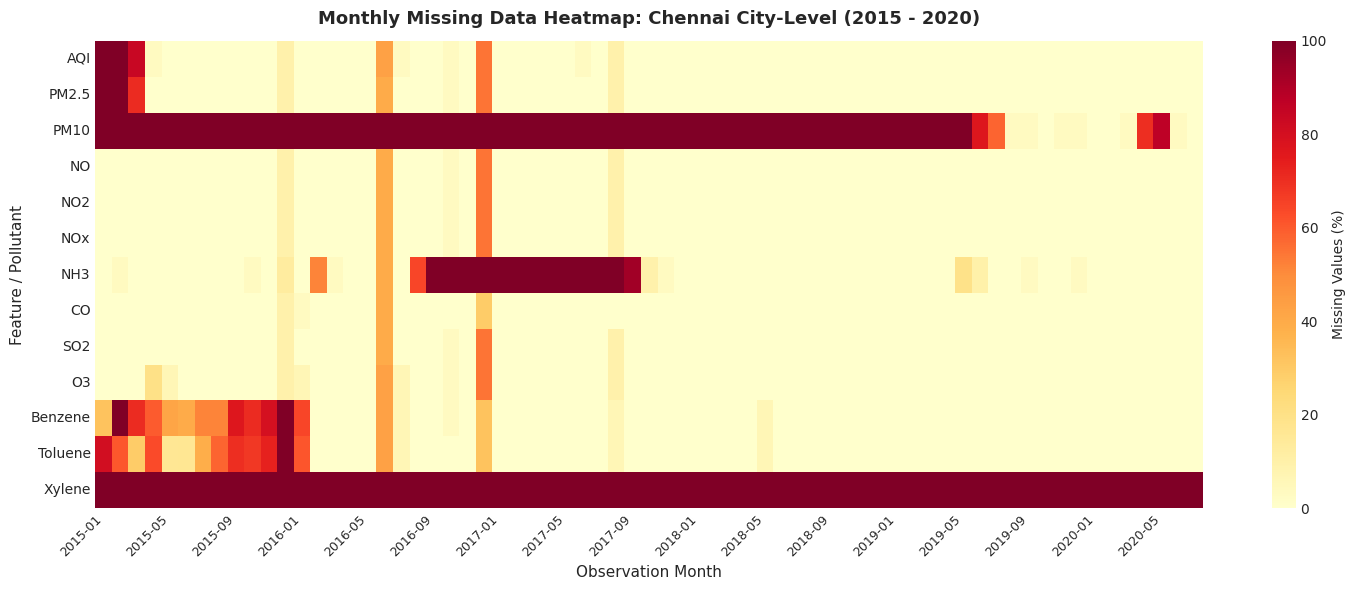

Saved: ../outputs/figures\p2_missing_value_heatmap.png


In [6]:
# 2. Missing-Value Heatmap for Selected Chennai City-Level Series
ch_city_pre = city_day_df[city_day_df['City'] == 'Chennai'].copy()
ch_city_pre['Date'] = pd.to_datetime(ch_city_pre['Date'])
ch_city_pre = ch_city_pre.set_index('Date').sort_index()

# Resample to monthly missingness rate
features_audit = ['AQI', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
monthly_missing = ch_city_pre[features_audit].resample('MS').apply(lambda x: (x.isna().sum() / len(x)) * 100)

plt.figure(figsize=(15, 6))
# Transpose so features are rows and dates are columns
sns.heatmap(monthly_missing.T, cmap='YlOrRd', vmin=0, vmax=100, cbar_kws={'label': 'Missing Values (%)'})
plt.title('Monthly Missing Data Heatmap: Chennai City-Level (2015 - 2020)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Observation Month', fontsize=11)
plt.ylabel('Feature / Pollutant', fontsize=11)

# Format x-tick labels for clarity
x_labels = [d.strftime('%Y-%m') if i % 4 == 0 else '' for i, d in enumerate(monthly_missing.index)]
plt.xticks(np.arange(len(x_labels)) + 0.5, x_labels, rotation=45, ha='right', fontsize=9)
plt.tight_layout()

fig_path_2 = os.path.join(FIG_DIR, 'p2_missing_value_heatmap.png')
plt.savefig(fig_path_2, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {fig_path_2}")

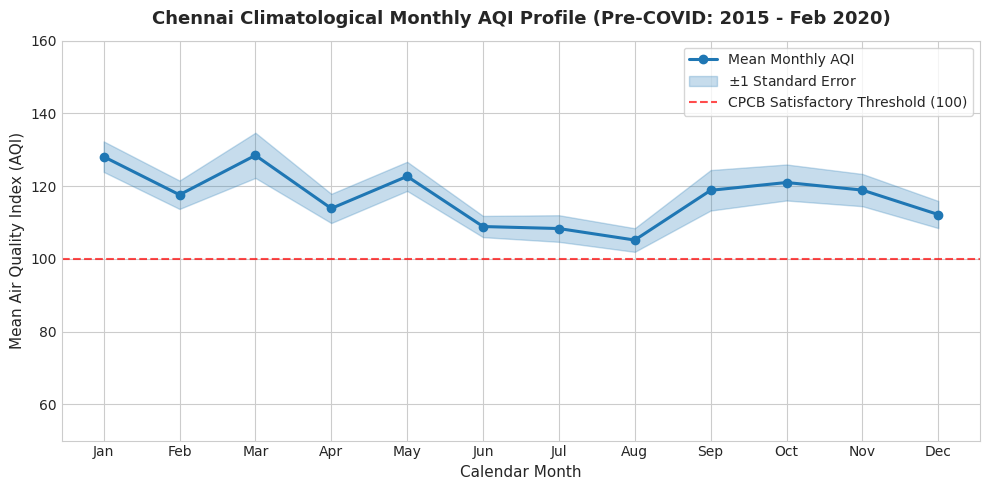

Saved: ../outputs/figures\p2_monthly_seasonality.png


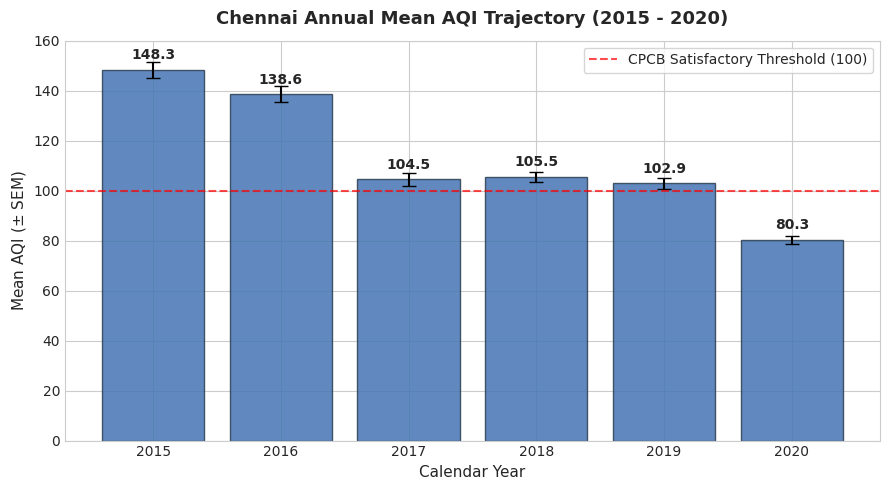

Saved: ../outputs/figures\p2_yearly_mean_aqi.png


In [7]:
# 3. Monthly Seasonality Profile
ch_pre = ch_city_pre.loc[:'2020-02-29'].copy()
ch_pre['Month'] = ch_pre.index.month
ch_pre['MonthName'] = ch_pre.index.strftime('%b')

monthly_stats = ch_pre.groupby('Month')['AQI'].agg(['mean', 'std', 'count']).reset_index()
monthly_stats['sem'] = monthly_stats['std'] / np.sqrt(monthly_stats['count'])
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_stats['MonthName'] = month_names

plt.figure(figsize=(10, 5))
plt.plot(monthly_stats['Month'], monthly_stats['mean'], marker='o', color='#1f77b4', linewidth=2.2, label='Mean Monthly AQI')
plt.fill_between(monthly_stats['Month'], monthly_stats['mean'] - monthly_stats['sem'], monthly_stats['mean'] + monthly_stats['sem'], color='#1f77b4', alpha=0.25, label='$\pm 1$ Standard Error')
plt.xticks(range(1, 13), month_names, fontsize=10)
plt.title('Chennai Climatological Monthly AQI Profile (Pre-COVID: 2015 - Feb 2020)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Calendar Month', fontsize=11)
plt.ylabel('Mean Air Quality Index (AQI)', fontsize=11)
plt.ylim(50, 160)
plt.axhline(100, color='red', linestyle='--', alpha=0.7, label='CPCB Satisfactory Threshold (100)')
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()

fig_path_3 = os.path.join(FIG_DIR, 'p2_monthly_seasonality.png')
plt.savefig(fig_path_3, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {fig_path_3}")

# 4. Yearly Mean AQI Bar Chart
ch_city_pre['Year'] = ch_city_pre.index.year
yearly_stats = ch_city_pre.groupby('Year')['AQI'].agg(['mean', 'std', 'count']).reset_index()

plt.figure(figsize=(9, 5))
bars = plt.bar(yearly_stats['Year'], yearly_stats['mean'], yerr=yearly_stats['std']/np.sqrt(yearly_stats['count']), 
               capsize=5, color='#4575b4', edgecolor='#2c3e50', alpha=0.85)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 3.0, f'{yval:.1f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Chennai Annual Mean AQI Trajectory (2015 - 2020)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Calendar Year', fontsize=11)
plt.ylabel('Mean AQI ($\pm$ SEM)', fontsize=11)
plt.axhline(100, color='red', linestyle='--', alpha=0.7, label='CPCB Satisfactory Threshold (100)')
plt.ylim(0, 160)
plt.legend(frameon=True)
plt.tight_layout()

fig_path_4 = os.path.join(FIG_DIR, 'p2_yearly_mean_aqi.png')
plt.savefig(fig_path_4, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {fig_path_4}")

## 5. COVID-19 Lockdown Impact Analysis
On **24 March 2020**, the Government of India instituted a nationwide lockdown in response to the COVID-19 pandemic. Industrial operations, vehicle transit, and commercial activities contracted precipitously, causing an unprecedented anthropogenic shock to atmospheric emission levels.

To validate keeping **1 March 2020 – 30 June 2020** aside as a dedicated stress-test window:
1. We compute the mean AQI during the strict lockdown window (**25 March – 31 May 2020**) and compare it directly to identical date windows in **2018** and **2019**.
2. We verify the completeness of valid AQI observations in the stress-test window.
3. We plot the lockdown trajectory to visualize the structural break.

COVID Lockdown Impact (25 March - 31 May):
  - 2020 Lockdown Mean AQI : 69.60 (n=68/68)
  - 2019 Baseline Mean AQI : 94.47 (n=68/68)
  - 2018 Baseline Mean AQI : 77.66 (n=68/68)
  - Absolute Change vs 2019: -24.87 points (-26.32%)
  - Absolute Change vs 2018: -8.06 points (-10.38%)
  - Change vs Combined Baseline: -16.46 points (-19.13%)

Stress-Test Window Completeness (1 March - 30 June 2020):
  - Valid Days : 122 / 122 (100.00%)
  - Missing Days: 0


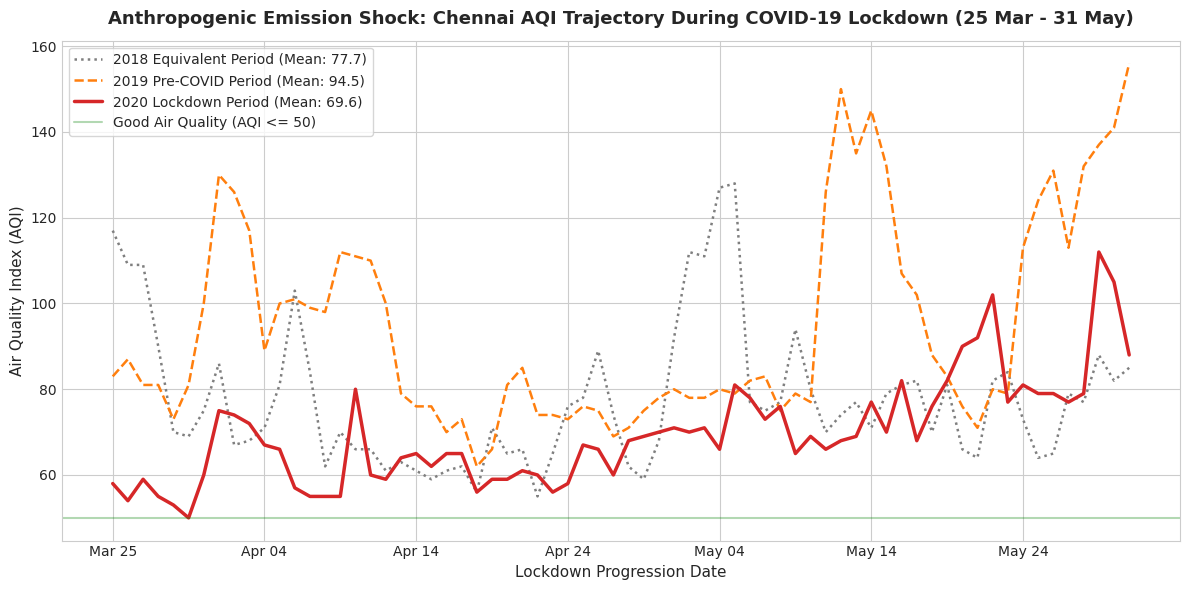

Saved: ../outputs/figures\p2_covid_lockdown_impact.png


In [8]:
# Extract exact comparative lockdown periods: March 25 - May 31
ld_2020 = ch_city_pre.loc['2020-03-25':'2020-05-31', 'AQI']
ld_2019 = ch_city_pre.loc['2019-03-25':'2019-05-31', 'AQI']
ld_2018 = ch_city_pre.loc['2018-03-25':'2018-05-31', 'AQI']

mean_2020 = ld_2020.mean()
mean_2019 = ld_2019.mean()
mean_2018 = ld_2018.mean()
baseline_18_19 = (mean_2018 + mean_2019) / 2.0

abs_change_19 = mean_2020 - mean_2019
pct_change_19 = (abs_change_19 / mean_2019) * 100

abs_change_18 = mean_2020 - mean_2018
pct_change_18 = (abs_change_18 / mean_2018) * 100

abs_change_base = mean_2020 - baseline_18_19
pct_change_base = (abs_change_base / baseline_18_19) * 100

# Stress-test window: 2020-03-01 to 2020-06-30
st_window = ch_city_pre.loc['2020-03-01':'2020-06-30', 'AQI']
st_valid_days = st_window.count()
st_total_days = len(st_window)

print(f"COVID Lockdown Impact (25 March - 31 May):")
print(f"  - 2020 Lockdown Mean AQI : {mean_2020:.2f} (n={ld_2020.count()}/{len(ld_2020)})")
print(f"  - 2019 Baseline Mean AQI : {mean_2019:.2f} (n={ld_2019.count()}/{len(ld_2019)})")
print(f"  - 2018 Baseline Mean AQI : {mean_2018:.2f} (n={ld_2018.count()}/{len(ld_2018)})")
print(f"  - Absolute Change vs 2019: {abs_change_19:+.2f} points ({pct_change_19:+.2f}%)")
print(f"  - Absolute Change vs 2018: {abs_change_18:+.2f} points ({pct_change_18:+.2f}%)")
print(f"  - Change vs Combined Baseline: {abs_change_base:+.2f} points ({pct_change_base:+.2f}%)")
print(f"\nStress-Test Window Completeness (1 March - 30 June 2020):")
print(f"  - Valid Days : {st_valid_days} / {st_total_days} ({st_valid_days/st_total_days*100:.2f}%)")
print(f"  - Missing Days: {st_window.isna().sum()}")

# 5. Lockdown Impact Plot
fig, ax = plt.subplots(figsize=(12, 6))

# Map day-of-year for direct overlay
days_ld = np.arange(1, len(ld_2020) + 1)
ax.plot(days_ld, ld_2018.values, label=f'2018 Equivalent Period (Mean: {mean_2018:.1f})', color='#7f7f7f', linestyle=':', linewidth=1.8)
ax.plot(days_ld, ld_2019.values, label=f'2019 Pre-COVID Period (Mean: {mean_2019:.1f})', color='#ff7f0e', linestyle='--', linewidth=1.8)
ax.plot(days_ld, ld_2020.values, label=f'2020 Lockdown Period (Mean: {mean_2020:.1f})', color='#d62728', linewidth=2.5)

# Formatting dates for tick marks
sample_dates = ld_2020.index.strftime('%b %d')
tick_indices = np.arange(0, len(ld_2020), 10)
ax.set_xticks(tick_indices + 1)
ax.set_xticklabels(sample_dates[tick_indices], fontsize=10)

ax.set_title('Anthropogenic Emission Shock: Chennai AQI Trajectory During COVID-19 Lockdown (25 Mar - 31 May)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Lockdown Progression Date', fontsize=11)
ax.set_ylabel('Air Quality Index (AQI)', fontsize=11)
ax.axhline(50, color='green', linestyle='-', alpha=0.3, label='Good Air Quality (AQI <= 50)')
ax.legend(frameon=True, fontsize=10)
plt.tight_layout()

fig_path_5 = os.path.join(FIG_DIR, 'p2_covid_lockdown_impact.png')
plt.savefig(fig_path_5, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {fig_path_5}")

## 6. Train / Validation / Test Split Verification
Time-series modeling requires strictly chronological partitions to prevent temporal data leakage. We audit the proposed split for the selected Chennai city-level series:
- **Training Set:** `2015-01-01` $\rightarrow$ `2018-12-31` (4 calendar years).
- **Validation Set:** `2019-01-01` $\rightarrow$ `2019-08-31` (8 calendar months, hyperparameter tuning).
- **Test Set:** `2019-09-01` $\rightarrow$ `2020-02-29` (6 calendar months, unseen evaluation).
- **Stress-Test Window:** `2020-03-01` $\rightarrow$ `2020-06-30` (4 calendar months, COVID-19 regime shift evaluation).

We report the total days, valid days, missingness, and statistical distribution ($\mu, \sigma$) across each partition.

In [9]:
split_definitions = {
    'Train': ('2015-01-01', '2018-12-31'),
    'Validation': ('2019-01-01', '2019-08-31'),
    'Test': ('2019-09-01', '2020-02-29'),
    'Stress Test': ('2020-03-01', '2020-06-30')
}

split_summary_list = []

for s_name, (start_dt, end_dt) in split_definitions.items():
    sub_series = ch_city_pre.loc[start_dt:end_dt, 'AQI']
    total_d = len(sub_series)
    valid_d = sub_series.count()
    miss_d = total_d - valid_d
    miss_pct = (miss_d / total_d) * 100
    
    split_summary_list.append({
        'Split Partition': s_name,
        'Start Date': start_dt,
        'End Date': end_dt,
        'Total Days': total_d,
        'Valid Days': valid_d,
        'Missing Days': miss_d,
        'Missing AQI (%)': round(miss_pct, 2),
        'Mean AQI': round(sub_series.mean(), 2),
        'Std AQI': round(sub_series.std(), 2),
        'Min AQI': round(sub_series.min(), 1),
        'Max AQI': round(sub_series.max(), 1)
    })

p2_split_summary_df = pd.DataFrame(split_summary_list)
p2_split_summary_df.to_csv(os.path.join(RES_DIR, 'p2_split_summary.csv'), index=False)
print("Saved split summary table to outputs/results/p2_split_summary.csv")
display(p2_split_summary_df)

# Verification assertions
train_days = p2_split_summary_df.loc[p2_split_summary_df['Split Partition'] == 'Train', 'Total Days'].values[0]
val_miss = p2_split_summary_df.loc[p2_split_summary_df['Split Partition'] == 'Validation', 'Missing AQI (%)'].values[0]
test_miss = p2_split_summary_df.loc[p2_split_summary_df['Split Partition'] == 'Test', 'Missing AQI (%)'].values[0]

print(f"\nSplit Verification Check:")
print(f"  - Training duration: {train_days} calendar days (Requirement: >= 700 days -> {'PASS' if train_days >= 700 else 'FAIL'})")
print(f"  - Validation completeness: {100 - val_miss:.1f}% valid (0.00% missing -> {'PASS' if val_miss == 0 else 'WARNING'})")
print(f"  - Test completeness: {100 - test_miss:.1f}% valid (0.00% missing -> {'PASS' if test_miss == 0 else 'WARNING'})")
print("Conclusion: Proposed split dates confirmed. No timeline adjustments required.")

Saved split summary table to outputs/results/p2_split_summary.csv


,Split Partition,Start Date,End Date,Total Days,Valid Days,Missing Days,Missing AQI (%),Mean AQI,Std AQI,Min AQI,Max AQI
0,Train,2015-01-01,2018-12-31,1461,1336,125,8.56,122.35,54.80,30.0,449.0
1,Validation,2019-01-01,2019-08-31,243,243,0,0.00,103.42,36.72,47.0,283.0
2,Test,2019-09-01,2020-02-29,182,182,0,0.00,95.73,45.03,47.0,306.0
3,Stress Test,2020-03-01,2020-06-30,122,122,0,0.00,78.81,20.38,50.0,169.0



Split Verification Check:
  - Training duration: 1461 calendar days (Requirement: >= 700 days -> PASS)
  - Validation completeness: 100.0% valid (0.00% missing -> PASS)
  - Test completeness: 100.0% valid (0.00% missing -> PASS)
Conclusion: Proposed split dates confirmed. No timeline adjustments required.


## 7. Pollutant Feature Selection for Multivariate LSTM
For the multivariate LSTM architecture, the target variable $y_t = 	ext{AQI}_t$ is supplemented by contemporaneous and lagged industrial pollutant concentrations $X_t$. 

We evaluate every candidate pollutant over the pre-COVID modeling window (`2015-01-01` to `2020-02-29`):
1. **Missingness Filter:** Pollutants with $>30\%$ missing values are rejected as unviable for time series modeling.
2. **Linear Association:** Pearson correlation with AQI ($r$).
3. **Collinearity / Redundancy Check:** Cross-correlation analysis to identify highly collinear pairs ($|r| > 0.90$, e.g. photochemical cycles between $\text{NO}$, $\text{NO}_2$, and $\text{NO}_x$).

In [10]:
ch_modeling = ch_city_pre.loc[:'2020-02-29'].copy()
pollutant_candidate_rows = []

for p in pollutants_all:
    miss_pct = (ch_modeling[p].isna().sum() / len(ch_modeling)) * 100
    corr_val = ch_modeling['AQI'].corr(ch_modeling[p])
    is_usable = miss_pct < 30.0
    
    pollutant_candidate_rows.append({
        'Pollutant': p,
        'Missing (%)': round(miss_pct, 2),
        'Pearson Corr (AQI)': round(corr_val, 4) if not np.isnan(corr_val) else np.nan,
        'Usable (<30% Missing)': is_usable,
        'Status': 'Recommended' if is_usable else 'Rejected (>30% missing)'
    })

p2_feature_candidates_df = pd.DataFrame(pollutant_candidate_rows)
p2_feature_candidates_df.to_csv(os.path.join(RES_DIR, 'p2_feature_candidates.csv'), index=False)
print("Saved feature candidates to outputs/results/p2_feature_candidates.csv")
display(p2_feature_candidates_df)

# Redundancy correlation matrix for usable candidates
usable_features = p2_feature_candidates_df[p2_feature_candidates_df['Usable (<30% Missing)']]['Pollutant'].tolist()
usable_corr_matrix = ch_modeling[usable_features].corr()

print("\nInter-Pollutant Correlation Matrix for Usable Features:")
display(usable_corr_matrix.round(3))

# Check for pairs with |r| > 0.90
redundant_pairs = []
for i in range(len(usable_features)):
    for j in range(i + 1, len(usable_features)):
        p1 = usable_features[i]
        p2 = usable_features[j]
        r_val = usable_corr_matrix.loc[p1, p2]
        if abs(r_val) > 0.90:
            redundant_pairs.append((p1, p2, r_val))

print(f"\nPairs with severe collinearity (|r| > 0.90): {len(redundant_pairs)}")
if redundant_pairs:
    for p1, p2, r in redundant_pairs:
        print(f"  - {p1} and {p2}: r = {r:.3f}")
else:
    print("  None detected. The maximum pairwise correlation is between NO and NO2 (r = 0.667 < 0.90). All 10 usable pollutants are distinct.")

Saved feature candidates to outputs/results/p2_feature_candidates.csv


,Pollutant,Missing (%),Pearson Corr (AQI),Usable (<30% Missing),Status
0,PM2.5,6.20,0.6741,True,Recommended
1,PM10,87.86,0.7097,False,Rejected (>30% missing)
2,NO,1.91,0.0998,True,Recommended
3,NO2,1.91,0.1538,True,Recommended
4,NOx,1.91,-0.0003,True,Recommended
5,NH3,24.50,0.0075,True,Recommended
6,CO,1.33,0.3515,True,Recommended
7,SO2,1.91,0.0746,True,Recommended
8,O3,2.60,0.2059,True,Recommended
9,Benzene,15.11,0.0268,True,Recommended



Inter-Pollutant Correlation Matrix for Usable Features:


,PM2.5,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
PM2.5,1.000,0.138,0.202,0.003,0.051,0.030,0.117,0.175,0.006,0.063
NO,0.138,1.000,0.667,0.419,-0.167,0.198,0.210,-0.112,0.001,0.081
NO2,0.202,0.667,1.000,0.439,-0.037,0.116,0.134,0.011,-0.014,0.037
NOx,0.003,0.419,0.439,1.000,-0.076,0.009,0.187,-0.092,-0.024,0.026
NH3,0.051,-0.167,-0.037,-0.076,1.000,-0.111,-0.029,0.038,-0.025,-0.020
CO,0.030,0.198,0.116,0.009,-0.111,1.000,0.048,0.001,0.086,0.134
SO2,0.117,0.210,0.134,0.187,-0.029,0.048,1.000,-0.002,0.042,0.007
O3,0.175,-0.112,0.011,-0.092,0.038,0.001,-0.002,1.000,-0.011,0.027
Benzene,0.006,0.001,-0.014,-0.024,-0.025,0.086,0.042,-0.011,1.000,0.144
Toluene,0.063,0.081,0.037,0.026,-0.020,0.134,0.007,0.027,0.144,1.000



Pairs with severe collinearity (|r| > 0.90): 0
  None detected. The maximum pairwise correlation is between NO and NO2 (r = 0.667 < 0.90). All 10 usable pollutants are distinct.


## 8. Summary of Findings & Next Steps
- **Selected Target Series:** Chennai City-Level series (`city_day.csv`). Manali station `TN003` was disqualified due to $31.28\%$ missingness and a 411-day gap; Station `TN002` was disqualified due to insufficient historical length (256 days).
- **Chronological Split:** Train ($1,461$ days, 2015–2018), Validation ($243$ days, Jan–Aug 2019, 0% missing), Test ($182$ days, Sep 2019 – Feb 2020, 0% missing), and Stress-Test ($122$ days, Mar–Jun 2020, 0% missing).
- **COVID-19 Impact:** During lockdown (25 Mar – 31 May 2020), Chennai AQI dropped by $26.32\%$ compared to 2019, confirming the decision to segregate this window.
- **Multivariate Features:** 10 pollutants selected for Phase 3 imputation and feature engineering (`PM2.5`, `NO`, `NO2`, `NOx`, `NH3`, `CO`, `SO2`, `O3`, `Benzene`, `Toluene`). `PM10` and `Xylene` were excluded due to excessive missingness.

This notebook concludes Phase 2. Proceed to **Phase 3: Preprocessing & Imputation** (`notebooks/03_preprocessing.ipynb`).